# Assignment 3 — Data preprocessing, in the right order

**Dataset:** UCI *Adult* (census income), classification of income `>50K` vs `<=50K`.
**Source link:** https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv (original: https://archive.ics.uci.edu/dataset/2/adult)

Why it fits the brief: 48,842 rows in the file, numeric + categorical columns, genuine missing values (`?` in `workclass`, `occupation`, `native_country`), and an imbalanced target (~24% positive).
To keep Colab fast (KNNImputer is slow on large data) I work on a **random 10,000-row sample** (`random_state=42`). Sampling happens before the split and fits nothing, so it does not leak.

**Rule followed everywhere:** every imputer, encoder, scaler and threshold is fitted on the training set only. The single exception is Question 9, where leakage is the thing being demonstrated.

In [1]:
%pip install -q imbalanced-learn

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from collections import Counter
from scipy.stats import skew
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler,
                                   RobustScaler, PowerTransformer, FunctionTransformer)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

SEED = 42
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv"
cols = ["age","workclass","fnlwgt","education","education_num","marital_status","occupation",
        "relationship","race","sex","capital_gain","capital_loss","hours_per_week","native_country","income"]
full = pd.read_csv(URL, header=None, names=cols, na_values="?", skipinitialspace=True)
print("full file:", full.shape)
df = full.sample(n=10_000, random_state=SEED).reset_index(drop=True)
print("working sample:", df.shape)
print("\nMissing values per column:"); print(df.isna().sum()[df.isna().sum() > 0])
print("\nTarget share:"); print(df["income"].value_counts(normalize=True).round(3))
df.head()

full file: (48842, 15)
working sample: (10000, 15)

Missing values per column:
workclass         588
occupation        589
native_country    182
dtype: int64

Target share:
income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,18,Private,423024,HS-grad,9,Never-married,Other-service,Not-in-family,White,Male,0,0,20,United-States,<=50K
1,17,Private,178953,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
2,25,Local-gov,348986,HS-grad,9,Never-married,Handlers-cleaners,Other-relative,Black,Male,0,0,40,United-States,<=50K
3,20,Private,218215,Some-college,10,Never-married,Sales,Own-child,White,Female,0,0,30,United-States,<=50K
4,47,Private,244025,HS-grad,9,Never-married,Machine-op-inspct,Unmarried,Amer-Indian-Eskimo,Male,0,0,56,Puerto-Rico,<=50K


## Q1. Split first (stratified, fixed `random_state`)

In [3]:
y = (df["income"] == ">50K").astype(int)
X = df.drop(columns="income")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape)
print("positive share  train: %.4f   test: %.4f" % (y_train.mean(), y_test.mean()))

train: (8000, 14)  test: (2000, 14)
positive share  train: 0.2412   test: 0.2410


**Why the split is the first step:** every statistic a preprocessing step learns (means, medians, category lists, quantiles) must come from training data only. If we compute them before splitting, information about the test rows leaks into the training pipeline.
Doing the split first makes it structurally impossible to forget this, because the test set simply is not there when anything is fitted.

## Q2. Three ways to handle missing values (all fitted on train only)

All the missing values in this dataset are in **categorical** columns (`workclass`, `occupation`, `native_country`). To make the numeric comparison the question asks for, I ordinal-encode those three columns (missing stays `NaN`) and then compare the three strategies on the encoded `occupation` column.
KNNImputer works on numbers, so it gets the six numeric columns + the three codes (standardised so no column dominates the distance), and its output is rounded back to a valid category code.

In [4]:
miss_cols = ["workclass", "occupation", "native_country"]
num_cols  = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
print("Missing in train:\n", X_train[miss_cols].isna().sum(), "\n")

oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                    encoded_missing_value=np.nan).fit(X_train[miss_cols])
M = pd.concat([X_train[num_cols].reset_index(drop=True),
               pd.DataFrame(oe.transform(X_train[miss_cols]), columns=miss_cols)], axis=1)

# (a) drop rows with any missing value among the three columns
A = M.dropna(subset=miss_cols)

# (b) fill with the most frequent value (the categorical analogue of mean/median)
B = pd.DataFrame(SimpleImputer(strategy="most_frequent").fit(M[miss_cols]).transform(M[miss_cols]), columns=miss_cols)

# (c) KNNImputer on standardised numeric + code columns
sc  = StandardScaler().fit(M)
knn = KNNImputer(n_neighbors=5).fit(sc.transform(M))
C   = pd.DataFrame(sc.inverse_transform(knn.transform(sc.transform(M))), columns=M.columns)[miss_cols].round()
for c, cats in zip(miss_cols, oe.categories_):
    C[c] = C[c].clip(0, len(cats) - 1)

col = "occupation"
modal = M[col].mode()[0]
rows = {"observed values only (reference)": M[col].dropna(),
        "(a) drop rows": A[col], "(b) most-frequent fill": B[col], "(c) KNNImputer": C[col]}
summary = pd.DataFrame({k: {"rows": len(v), "mean": v.mean(), "std": v.std(),
                            "share of modal category": (v == modal).mean()} for k, v in rows.items()}).T
print("Encoded column:", col, "| modal category:", oe.categories_[1][int(modal)])
summary.round(4)

Missing in train:
 workclass         468
occupation        469
native_country    142
dtype: int64 



Encoded column: occupation | modal category: Craft-repair


,rows,mean,std,share of modal category
observed values only (reference),7531.0,5.9053,3.9834,0.1381
(a) drop rows,7400.0,5.8943,3.9867,0.1386
(b) most-frequent fill,8000.0,5.6764,3.9723,0.1886
(c) KNNImputer,8000.0,5.9117,3.8898,0.1314


**Reading the table.** The observed values have mean 5.905, std 3.983 and a modal-category share of 13.8%.
- (a) Dropping rows stays close to the observed numbers, but throws away 600 training rows (7.5%), and it cannot be used at prediction time because a new customer with a missing value still needs a prediction.
- (b) Most-frequent fill distorts the distribution: the modal share jumps from 13.8% to 18.9% and the mean drops to 5.68, because about 470 rows were all given the same value.
- (c) KNNImputer matches the original distribution best (mean 5.912, modal share 13.1%), but it measures "nearness" using category codes that are alphabetical and have no real order, and it is the slowest.

**Which I would keep:** on these numbers (c) is the most faithful, but (b) is the one I put in the final pipeline: it is simple, fast, and works unchanged on a single new row. I accept its distortion of `occupation` and say so in Q12. If this were a real project, I would try a constant `"Unknown"` category instead, since missingness itself may carry signal.

## Q3. Outliers in `fnlwgt` — IQR rule vs z-score vs 1st/99th percentile cap

In [5]:
x = X_train["fnlwgt"]
q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
p1, p99 = x.quantile([.01, .99])
flags = pd.DataFrame({
    "IQR (1.5x)":      (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr),
    "z-score (|z|>3)": ((x - x.mean()) / x.std()).abs() > 3,
    "percentile 1/99": (x < p1) | (x > p99)})
print("Rows flagged by each method (out of %d):" % len(x)); print(flags.sum().to_string())
print("\nOverlap matrix (diagonal = total flagged by that method):")
print((flags.T.astype(int) @ flags.astype(int)).to_string())
print("\nflagged by all three:", int(flags.all(axis=1).sum()), "| flagged by at least one:", int(flags.any(axis=1).sum()))
print("\nBefore vs after capping at the 1st/99th percentile (thresholds from train: %.0f, %.0f)" % (p1, p99))
pd.DataFrame({"raw": x.describe(), "capped": x.clip(p1, p99).describe()}).round(1)

Rows flagged by each method (out of 8000):
IQR (1.5x)         245
z-score (|z|>3)     72
percentile 1/99    159

Overlap matrix (diagonal = total flagged by that method):
                 IQR (1.5x)  z-score (|z|>3)  percentile 1/99
IQR (1.5x)              245               72               80
z-score (|z|>3)          72               72               72
percentile 1/99          80               72              159

flagged by all three: 72 | flagged by at least one: 324

Before vs after capping at the 1st/99th percentile (thresholds from train: 26252, 485150)


,raw,capped
count,8000.0,8000.0
mean,187037.2,185996.9
std,103218.8,98612.4
min,19302.0,26252.0
25%,115474.2,115474.2
50%,177588.5,177588.5
75%,234290.0,234290.0
max,1117718.0,485150.4


**Reading the output.** The IQR rule flags 245 rows (3.1%), the z-score rule 72 (0.9%), and the percentile rule 159 (2.0%). All 72 z-score rows are also flagged by the other two methods, and the percentile rule overlaps with IQR on only 80 rows; 324 rows are flagged by at least one method and 72 by all three.

**Chosen: capping at the 1st/99th percentile.** `fnlwgt` is a survey weight with a naturally right-skewed shape, so its large values are not errors, and deleting 245 rows (IQR) would cut real data. The z-score rule flags few rows because the tail inflates the standard deviation itself. Capping keeps every row, uses thresholds learned from train (26,252 and 485,150), and brings the maximum from 1,117,718 down to 485,150 while leaving the quartiles untouched.

## Q4. Encoding: one-hot, ordinal with explicit order, frequency

In [6]:
edu_order = ["Preschool","1st-4th","5th-6th","7th-8th","9th","10th","11th","12th","HS-grad",
             "Some-college","Assoc-voc","Assoc-acdm","Bachelors","Masters","Prof-school","Doctorate"]
ohe  = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_train[["marital_status"]])
ordc = OrdinalEncoder(categories=[edu_order], handle_unknown="use_encoded_value", unknown_value=-1).fit(X_train[["education"]])
freq_map = X_train["native_country"].fillna("Missing").value_counts(normalize=True)
print("unique values -> marital_status: %d | education: %d | native_country: %d" %
      (X_train.marital_status.nunique(), X_train.education.nunique(), X_train.native_country.nunique()))

s0 = X_train.copy()
print("start:                                   ", s0.shape[1], "columns")
oh = pd.DataFrame(ohe.transform(s0[["marital_status"]]), columns=ohe.get_feature_names_out(["marital_status"]), index=s0.index)
s1 = pd.concat([s0.drop(columns="marital_status"), oh], axis=1)
print("after one-hot (marital_status):          ", s1.shape[1], "columns")
s2 = s1.assign(education=ordc.transform(s0[["education"]]).ravel())
print("after ordinal (education, explicit order):", s2.shape[1], "columns")
s3 = s2.assign(native_country=s0["native_country"].fillna("Missing").map(freq_map).fillna(0.0))
print("after frequency (native_country):        ", s3.shape[1], "columns")
s3[["education", "native_country"]].head()

unique values -> marital_status: 7 | education: 16 | native_country: 41
start:                                    14 columns
after one-hot (marital_status):           20 columns
after ordinal (education, explicit order): 20 columns
after frequency (native_country):         20 columns


,education,native_country
1707,5.0,0.891375
2509,8.0,0.002500
710,12.0,0.891375
6673,9.0,0.891375
2676,3.0,0.891375


## Q5. A category that appears in test but never in train

In [7]:
def encode(X):
    """Apply the three encoders fitted on train. Unseen categories never raise."""
    out = X.copy()
    oh = pd.DataFrame(ohe.transform(out[["marital_status"]]), columns=ohe.get_feature_names_out(["marital_status"]), index=out.index)
    out = pd.concat([out.drop(columns="marital_status"), oh], axis=1)
    out["education"] = ordc.transform(X[["education"]]).ravel()                              # unseen -> -1
    out["native_country"] = X["native_country"].fillna("Missing").map(freq_map).fillna(0.0)  # unseen -> 0.0
    return out
# sanity: same result as the step-by-step version on train
assert encode(X_train).shape[1] == s3.shape[1]

# Unseen categories that really occur in this test split:
for c in ["marital_status", "education", "native_country"]:
    print("real unseen in test for %-15s:" % c, set(X_test[c].dropna()) - set(X_train[c].dropna()) or "none")

# Force the issue with made-up categories:
X_bad = X_test.head(5).copy()
X_bad["marital_status"], X_bad["education"], X_bad["native_country"] = "Time-traveller", "Wizard-school", "Atlantis"

try:
    OneHotEncoder(handle_unknown="error").fit(X_train[["marital_status"]]).transform(X_bad[["marital_status"]])
except ValueError as e:
    print("\nDefault OneHotEncoder crashes ->", str(e)[:70], "...")

enc_bad = encode(X_bad)   # does NOT crash
print("\nOur encoder on unseen categories: no crash. Result:")
enc_bad[[c for c in enc_bad.columns if c.startswith("marital_status_")] + ["education", "native_country"]]

real unseen in test for marital_status : none
real unseen in test for education      : none
real unseen in test for native_country : none

Default OneHotEncoder crashes -> Found unknown categories ['Time-traveller'] in column 0 during transfo ...

Our encoder on unseen categories: no crash. Result:


,marital_status_Divorced,marital_status_Married-AF-spouse,marital_status_Married-civ-spouse,marital_status_Married-spouse-absent,marital_status_Never-married,marital_status_Separated,marital_status_Widowed,education,native_country
5363,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0
1573,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0
5733,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0
2145,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0
5899,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0


## Q6. Scaling a skewed column (`fnlwgt`)

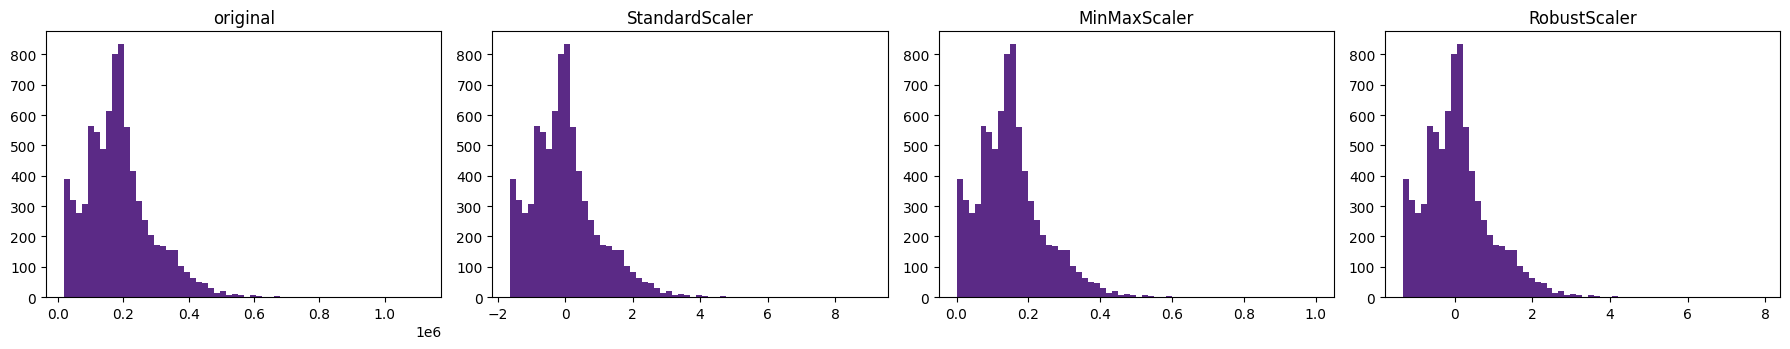

,median,IQR (spread of the bulk),min,max
original,177588.500,118815.750,19302.000,1117718.000
StandardScaler,-0.092,1.151,-1.625,9.017
MinMaxScaler,0.144,0.108,0.000,1.000
RobustScaler,0.000,1.000,-1.332,7.912


In [8]:
v = X_train[["fnlwgt"]]
scaled = {"original": v["fnlwgt"].to_numpy()}
for name, s in [("StandardScaler", StandardScaler()), ("MinMaxScaler", MinMaxScaler()), ("RobustScaler", RobustScaler())]:
    scaled[name] = s.fit(v).transform(v).ravel()
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, (k, arr) in zip(axes, scaled.items()):
    ax.hist(arr, bins=60, color="#5b2a86"); ax.set_title(k)
plt.tight_layout(); plt.show()
pd.DataFrame({k: {"median": np.median(a), "IQR (spread of the bulk)": np.subtract(*np.percentile(a, [75, 25])),
                  "min": a.min(), "max": a.max()} for k, a in scaled.items()}).T.round(3)

**RobustScaler handles the outliers best.** It centres on the median and divides by the IQR, so a few huge values cannot change the scale: the bulk of the data keeps a spread of exactly 1.0. With MinMaxScaler the single largest value (1.1M) defines the range, so the bulk is squeezed into a spread of only 0.108. StandardScaler sits in between (mean and std are both pulled by the tail). Note that no scaler removes the outliers; RobustScaler just stops them from distorting everything else.

## Q7. Skewness: `log1p` vs Yeo-Johnson

In [9]:
rows = []
for c in ["capital_gain", "fnlwgt"]:
    v = X_train[[c]]
    pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(v)   # fitted on train only
    rows.append({"column": c, "original": skew(v[c]), "after log1p": skew(np.log1p(v[c])),
                 "after Yeo-Johnson": skew(pt.transform(v).ravel()), "YJ lambda": pt.lambdas_[0]})
pd.DataFrame(rows).set_index("column").round(3)

,original,after log1p,after Yeo-Johnson,YJ lambda
column,,,,
capital_gain,12.670,3.239,3.164,-1.462
fnlwgt,1.196,-0.859,0.002,0.445


**Reading the table.** `fnlwgt` (skew 1.20) is fixed well by Yeo-Johnson (0.002), while `log1p` overshoots to -0.86 and leaves it skewed the other way. `capital_gain` (skew 12.67) improves a lot with both (3.24 with `log1p`, 3.16 with Yeo-Johnson) but stays skewed, because most of its values are exactly 0, and no power transform can spread a spike of identical values. In the pipeline I use `log1p` on `capital_gain` and `capital_loss`: it is simple, needs no fitting, and keeps zero as zero.

## Q8. One `ColumnTransformer` inside a `Pipeline`: impute + encode + scale

The frequency encoder is not in scikit-learn, so it lives in a tiny module, `freq_encoder.py`, written by the next cell. It is a separate file so that `pipeline.joblib` can be loaded anywhere that file sits next to it (a pickled class has to be importable).

In [10]:
%%writefile freq_encoder.py
import numpy as np, pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

class FrequencyEncoder(TransformerMixin, BaseEstimator):
    """Replace each category by its relative frequency in the training data.
    Missing values count as their own category; unseen categories map to 0."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = list(X.columns)
        self.maps_ = {c: X[c].fillna("Missing").value_counts(normalize=True).to_dict() for c in self.columns_}
        return self
    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_)
        return np.column_stack([X[c].fillna("Missing").map(self.maps_[c]).fillna(0.0).to_numpy(dtype=float)
                                for c in self.columns_])
    def get_feature_names_out(self, input_features=None):
        return np.array([f"{c}_freq" for c in self.columns_])

Overwriting freq_encoder.py


In [11]:
from freq_encoder import FrequencyEncoder

robust_num   = ["age", "fnlwgt", "hours_per_week"]
skewed_num   = ["capital_gain", "capital_loss"]            # Q7: heavy right skew -> log1p first
onehot_cols  = ["workclass", "marital_status", "occupation", "relationship", "race", "sex"]
ordinal_cols = ["education"]                               # replaces education_num (same information)
freq_cols    = ["native_country"]

preprocess = ColumnTransformer([
    ("num_robust", Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("scale",  RobustScaler())]), robust_num),
    ("num_skewed", Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("log",    FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                             ("scale",  StandardScaler())]), skewed_num),
    ("cat_onehot", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), onehot_cols),
    ("cat_ordinal", OrdinalEncoder(categories=[edu_order], handle_unknown="use_encoded_value", unknown_value=-1), ordinal_cols),
    ("cat_freq", FrequencyEncoder(), freq_cols),
], remainder="drop")
pipeline = Pipeline([("preprocess", preprocess)])

X_train_t = pipeline.fit(X_train).transform(X_train)     # fit on train ONLY
X_test_t  = pipeline.transform(X_test)                   # test is only transformed
print("train output:", X_train_t.shape, "| test output:", X_test_t.shape)
assert X_train_t.shape[1] == X_test_t.shape[1], "column counts must match"
assert not np.isnan(X_train_t).any() and not np.isnan(X_test_t).any()
feature_names = pipeline.get_feature_names_out()
print(len(feature_names), "output columns, e.g.:", list(feature_names[:6]), "...")

train output: (8000, 49) | test output: (2000, 49)
49 output columns, e.g.: ['num_robust__age', 'num_robust__fnlwgt', 'num_robust__hours_per_week', 'num_skewed__capital_gain', 'num_skewed__capital_loss', 'cat_onehot__workclass_Federal-gov'] ...


## Q9. Leakage, demonstrated (`fnlwgt`, first five test rows)

In [12]:
col = ["fnlwgt"]
leaky   = StandardScaler().fit(df[col])          # WRONG: fitted on the full data, test rows included
correct = StandardScaler().fit(X_train[col])     # RIGHT: fitted on train only
a = leaky.transform(X_test[col]).ravel()[:5]
b = correct.transform(X_test[col]).ravel()[:5]
print("leaky   (full-data scaler) :", a.round(6))
print("correct (train-only scaler):", b.round(6))
print("difference                 :", (a - b).round(6))
print("\nmean/std used -> leaky: %.1f / %.1f | correct: %.1f / %.1f" %
      (leaky.mean_[0], leaky.scale_[0], correct.mean_[0], correct.scale_[0]))
print("max |difference| over the whole test set: %.6f" % np.abs(leaky.transform(X_test[col]) - correct.transform(X_test[col])).max())

leaky   (full-data scaler) : [ 0.131428  2.377426 -1.037807  0.023689 -1.398937]
correct (train-only scaler): [ 0.145416  2.424553 -1.041069  0.036088 -1.407528]
difference                 : [-0.013989 -0.047126  0.003262 -0.012399  0.00859 ]

mean/std used -> leaky: 188280.9 / 104735.2 | correct: 187037.2 / 103212.4
max |difference| over the whole test set: 0.177972


**Why the first version makes the test score a lie:**
1. The leaky scaler's mean and standard deviation were computed using the test rows themselves, so the "unseen" data has already influenced how the training data is prepared.
2. The test set no longer behaves like future data: in production you will never get to recompute statistics on rows that have not arrived yet, so the score you measured is one you cannot reproduce.
3. The gap above is small only because this is a large, well-behaved sample and a plain scaler. With small data, or with learned steps such as KNN imputation, target encoding or feature selection, the same mistake can inflate scores badly.

## Q10. Class imbalance and SMOTE (training set only)

In [13]:
print("Class counts (full sample):", dict(Counter(y)), "| ratio majority:minority = %.2f : 1" % (Counter(y)[0] / Counter(y)[1]))
print("Train counts BEFORE SMOTE :", dict(Counter(y_train)))
X_train_sm, y_train_sm = SMOTE(random_state=SEED).fit_resample(X_train_t, y_train)   # train only
print("Train counts AFTER  SMOTE :", dict(Counter(y_train_sm)), "| shape", X_train_sm.shape)
print("Test counts (untouched)   :", dict(Counter(y_test)), "| shape", X_test_t.shape)

Class counts (full sample): {0: 7588, 1: 2412} | ratio majority:minority = 3.15 : 1
Train counts BEFORE SMOTE : {0: 6070, 1: 1930}
Train counts AFTER  SMOTE : {0: 6070, 1: 6070} | shape (12140, 49)
Test counts (untouched)   : {0: 1518, 1: 482} | shape (2000, 49)


**Why the test set is left untouched:** the test set is our stand-in for real future data, and real data is imbalanced, with no synthetic minority rows. Resampling it would measure performance on a world that does not exist, and SMOTE rows are built from neighbours, so synthetic test points would be near-copies of each other and of training points.
SMOTE here runs on the already-encoded numeric matrix; one-hot columns of synthetic rows become fractional, which is a known limitation (`SMOTENC` handles categoricals natively if needed).

## Q11. Save the fitted pipeline, reload it, transform one raw row

In [14]:
joblib.dump(pipeline, "pipeline.joblib")      # the pipeline fitted on train in Q8
import os; print("saved pipeline.joblib,", os.path.getsize("pipeline.joblib") // 1024, "KB")

saved pipeline.joblib, 8 KB


In [15]:
# --- "fresh cell": only the saved file and raw data are used ---
import joblib, pandas as pd, numpy as np
loaded = joblib.load("pipeline.joblib")
new_row = pd.DataFrame([{"age": 41, "workclass": "Private", "fnlwgt": 190000, "education": "Bachelors", "education_num": 13,
                         "marital_status": "Married-civ-spouse", "occupation": np.nan,        # missing on purpose
                         "relationship": "Husband", "race": "White", "sex": "Male", "capital_gain": 0,
                         "capital_loss": 0, "hours_per_week": 45, "native_country": "United-States"}])
out = loaded.transform(new_row)
print("raw row -> model-ready vector of shape", out.shape, "| NaN present:", bool(np.isnan(out).any()))
pd.Series(out.ravel(), index=loaded.get_feature_names_out()).loc[lambda s: s != 0].round(3)

raw row -> model-ready vector of shape (1, 49) | NaN present: False


num_robust__age                                   0.200
num_robust__fnlwgt                                0.104
num_robust__hours_per_week                        1.000
num_skewed__capital_gain                         -0.288
num_skewed__capital_loss                         -0.226
cat_onehot__workclass_Private                     1.000
cat_onehot__marital_status_Married-civ-spouse     1.000
cat_onehot__occupation_Craft-repair               1.000
cat_onehot__relationship_Husband                  1.000
cat_onehot__race_White                            1.000
cat_onehot__sex_Male                              1.000
cat_ordinal__education                           12.000
cat_freq__native_country_freq                     0.891
dtype: float64

In [16]:
try:
    from google.colab import files
    files.download("pipeline.joblib")
except ImportError:
    print("Not running in Colab: pipeline.joblib is in the working directory.")

Not running in Colab: pipeline.joblib is in the working directory.


## Q12. My choices and why

- **Q2 — missing values:** keep **most-frequent fill** inside the pipeline. KNNImputer preserved the distribution best (mean 5.912 vs 5.905 observed, modal share 13.1% vs 13.8%), but its distances run over meaningless alphabetical codes and it is slow. Dropping rows loses 7.5% of train and fails on new rows. Most-frequent fill is the cheapest option that works at prediction time, at the cost of inflating the modal share of `occupation` from 13.8% to 18.9%.
- **Q3 — outliers:** keep **capping at the 1st/99th percentile** (thresholds 26,252 / 485,150 from train), because IQR would flag 245 rows of legitimate survey weights and z-score only catches 72 since the tail inflates the std. Because the final pipeline stays imputing + encoding + scaling as the brief says, the cap itself is not inside it; outlier influence there is handled by `RobustScaler` and `log1p`.
- **Q6 — scaling:** keep **RobustScaler** for skewed columns with outliers: the bulk of `fnlwgt` keeps a spread of 1.0, versus 0.108 under MinMaxScaler where one 1.1M value squeezes everything else.